# 02 — Baseline Predictive Model and Supporting Figures

**Project:** Lab Test Recommendation System — predicting diabetes-range HbA1c from CBC + demographics
**Feeds:** Section 5 (Preliminary Results) and Section 4 (Proposed Methods and Evaluation) of the
Midterm Research Plan.

This notebook extends `01_eda_cbc_glucose_demographics.ipynb` with (1) a correlation heatmap of
CBC parameters, (2) exploratory classifiers comparing age-only and demographics-only models
against CBC+demographics models, and (3) the sensitivity/specificity/NPV evaluation across
thresholds that Section 4 commits to using (not overall accuracy alone).

**Important caveat, stated explicitly so it isn't lost:** this is an *exploratory* pass. NHANES
survey weights are not applied, the HbA1c >= 6.5% primary target and intended screening population still need team
confirmation (see README "Known Uncertainties"), and no
hyperparameter tuning, full cross-validation, or confidence intervals have been run yet. Treat the
numbers here as a feasibility signal, not a final result.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110
DATA_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CODEX.md').is_file()) / 'data/raw/2021_2023'


## 1. Load and merge (same five NHANES components as notebook 01)

In [2]:
demo = pd.read_sas(DATA_DIR / "DEMO_L.xpt", format="xport")
cbc  = pd.read_sas(DATA_DIR / "CBC_L.xpt",  format="xport")
glu  = pd.read_sas(DATA_DIR / "GLU_L.xpt",  format="xport")
ghb  = pd.read_sas(DATA_DIR / "GHB_L.xpt",  format="xport")
diq  = pd.read_sas(DATA_DIR / "DIQ_L.xpt",  format="xport")

demo_cols = {"SEQN": "SEQN", "RIAGENDR": "sex", "RIDAGEYR": "age_years",
             "RIDRETH3": "race_eth", "DMDEDUC2": "education", "INDFMPIR": "income_pir"}
cbc_cols = {"SEQN": "SEQN", "LBXWBCSI": "wbc", "LBXRBCSI": "rbc", "LBXHGB": "hemoglobin",
            "LBXHCT": "hematocrit", "LBXMCVSI": "mcv", "LBXRDW": "rdw", "LBXPLTSI": "platelet",
            "LBXLYPCT": "lymph_pct", "LBXNEPCT": "neut_pct", "LBXMOPCT": "mono_pct",
            "LBXEOPCT": "eos_pct", "LBXBAPCT": "baso_pct"}
glu_cols = {"SEQN": "SEQN", "LBXGLU": "fasting_glucose_mgdl"}
ghb_cols = {"SEQN": "SEQN", "LBXGH": "hba1c_pct"}
diq_cols = {"SEQN": "SEQN", "DIQ010": "dx_diabetes"}

demo_s = demo[list(demo_cols)].rename(columns=demo_cols)
cbc_s  = cbc[list(cbc_cols)].rename(columns=cbc_cols)
glu_s  = glu[list(glu_cols)].rename(columns=glu_cols)
ghb_s  = ghb[list(ghb_cols)].rename(columns=ghb_cols)
diq_s  = diq[list(diq_cols)].rename(columns=diq_cols)

df = (demo_s.merge(cbc_s, on="SEQN", how="left")
            .merge(glu_s, on="SEQN", how="left")
            .merge(ghb_s, on="SEQN", how="left")
            .merge(diq_s, on="SEQN", how="left"))

# DMDEDUC2 codes 7 ("Refused") and 9 ("Don't know") are not education levels -- without this,
# they'd be fed into the model as if "9" meant more education than "5" (College graduate or above).
n_sentinel = df["education"].isin([7, 9]).sum()
df.loc[df["education"].isin([7, 9]), "education"] = np.nan
print(f"Merged sample: {len(df)} participants")
print(f"Recoded {n_sentinel} 'refused'/'don't know' education sentinel codes to missing")


Merged sample: 11933 participants
Recoded 11 'refused'/'don't know' education sentinel codes to missing


## 2. Define the modeling sample and an *exploratory* target

We use HbA1c >= 6.5% as the exploratory positive label, restricted to rows with a complete CBC
panel. This is NOT the team's final target-label decision (Section 4 of the Research Plan lists
three candidates still under discussion) — HbA1c is used here only because it has the largest
usable paired sample with CBC (see notebook 01, Table/coverage check).

In [3]:
cbc_vars = ["wbc", "rbc", "hemoglobin", "hematocrit", "mcv", "rdw", "platelet",
            "lymph_pct", "neut_pct", "mono_pct", "eos_pct", "baso_pct"]
demo_vars = ["age_years", "sex", "race_eth", "education", "income_pir"]

model_df = df.dropna(subset=["hba1c_pct"] + cbc_vars).copy()
model_df["target"] = (model_df["hba1c_pct"] >= 6.5).astype(int)

print(f"Modeling sample (complete CBC panel + HbA1c present): {len(model_df)}")
print(f"Positive class (HbA1c >= 6.5%, exploratory label): {model_df['target'].sum()} "
      f"({100*model_df['target'].mean():.1f}%)")


Modeling sample (complete CBC panel + HbA1c present): 6678
Positive class (HbA1c >= 6.5%, exploratory label): 717 (10.7%)


## 3. Correlation heatmap — CBC parameters + age/income

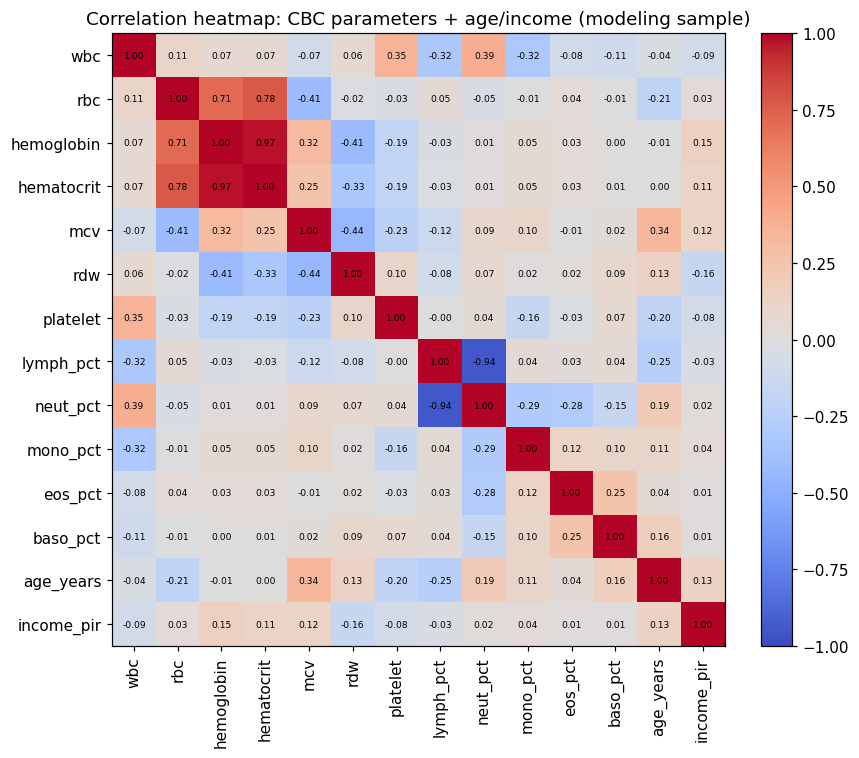

In [4]:
numeric_for_corr = cbc_vars + ["age_years", "income_pir"]
corr = model_df[numeric_for_corr].corr()

plt.figure(figsize=(9, 7))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(numeric_for_corr)), numeric_for_corr, rotation=90)
plt.yticks(range(len(numeric_for_corr)), numeric_for_corr)
for i in range(len(numeric_for_corr)):
    for j in range(len(numeric_for_corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.title("Correlation heatmap: CBC parameters + age/income (modeling sample)")
plt.tight_layout()
plt.show()


## 4. Train/test split and preprocessing pipelines

75/25 stratified split. Numeric features are median-imputed and standardized; categorical
features are mode-imputed (no further encoding needed for tree models; logistic regression
treats the NHANES integer category codes as ordinal, which is a simplification the team should
revisit — e.g., one-hot encoding race/education — before the final report).

In [5]:
X = model_df[cbc_vars + demo_vars].copy()
y = model_df["target"].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Train: {len(X_train)}   Test: {len(X_test)}")

numeric_features = cbc_vars + ["age_years", "income_pir"]
categorical_features = ["sex", "race_eth", "education"]

def make_pipeline(numeric_cols, categorical_cols, clf):
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent"))]), categorical_cols),
    ])
    return Pipeline([("pre", pre), ("clf", clf)])


Train: 5008   Test: 1670


## 5. Ablation: age-only, demographics-only, and CBC+demographics

All four models use the same complete-CBC cohort and fixed train/test split. The age-only
logistic baseline measures how much discrimination is available from age alone. Comparing the
two multivariable logistic models more directly isolates the incremental contribution of CBC;
the random forest also changes the model family. All classifiers retain balanced class weights.


In [6]:
age_only_pipe = make_pipeline(["age_years"], [],
                              LogisticRegression(class_weight="balanced", max_iter=2000))
age_only_pipe.fit(X_train[["age_years"]], y_train)
proba_age = age_only_pipe.predict_proba(X_test[["age_years"]])[:, 1]
auc_age = roc_auc_score(y_test, proba_age)
print(f"Age-only logistic regression AUROC: {auc_age:.3f}")

demo_only_pipe = make_pipeline(demo_vars[:1] + ["income_pir"], ["sex", "race_eth", "education"],
                                LogisticRegression(class_weight="balanced", max_iter=2000))
demo_only_pipe.fit(X_train[demo_vars], y_train)
proba_demo = demo_only_pipe.predict_proba(X_test[demo_vars])[:, 1]
auc_demo = roc_auc_score(y_test, proba_demo)
print(f"Demographics-only logistic regression AUROC: {auc_demo:.3f}")

full_logreg_pipe = make_pipeline(numeric_features, categorical_features,
                                  LogisticRegression(class_weight="balanced", max_iter=2000))
full_logreg_pipe.fit(X_train, y_train)
proba_full_lr = full_logreg_pipe.predict_proba(X_test)[:, 1]
auc_full_lr = roc_auc_score(y_test, proba_full_lr)
print(f"CBC + demographics logistic regression AUROC: {auc_full_lr:.3f}")

rf_pipe = make_pipeline(numeric_features, categorical_features,
                         RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                 random_state=42, min_samples_leaf=5))
rf_pipe.fit(X_train, y_train)
proba_rf = rf_pipe.predict_proba(X_test)[:, 1]
auc_rf = roc_auc_score(y_test, proba_rf)
print(f"CBC + demographics random forest AUROC: {auc_rf:.3f}")

model_scores = {
    "Age only (logistic)": proba_age,
    "Demographics only (logistic)": proba_demo,
    "CBC + demographics (logistic)": proba_full_lr,
    "CBC + demographics (random forest)": proba_rf,
}
assets_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CODEX.md').is_file()) / 'results/baseline'
assets_dir.mkdir(exist_ok=True)
auc_table = pd.DataFrame([
    {"model": name, "AUROC": roc_auc_score(y_test, scores),
     "AUROC_gain_over_age": roc_auc_score(y_test, scores) - auc_age}
    for name, scores in model_scores.items()
])
print(auc_table.round(3).to_string(index=False))
auc_table.to_csv(assets_dir / "baseline_auroc_comparison.csv", index=False)


Age-only logistic regression AUROC: 0.689
Demographics-only logistic regression AUROC: 0.743
CBC + demographics logistic regression AUROC: 0.783
CBC + demographics random forest AUROC: 0.811
                             model  AUROC  AUROC_gain_over_age
               Age only (logistic)  0.689                0.000
      Demographics only (logistic)  0.743                0.054
     CBC + demographics (logistic)  0.783                0.094
CBC + demographics (random forest)  0.811                0.122


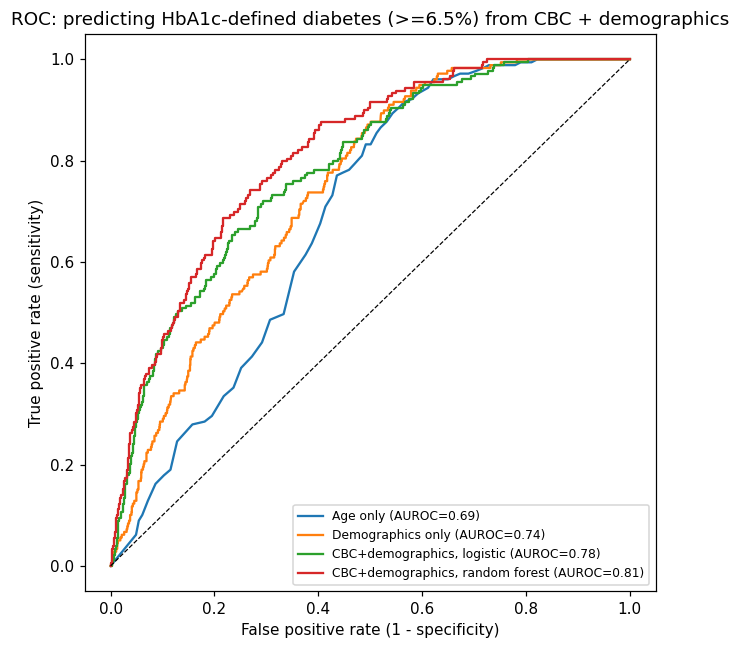

In [7]:
plt.figure(figsize=(6, 6))
for proba, label in [(proba_age, f"Age only (AUROC={auc_age:.2f})"),
                      (proba_demo, f"Demographics only (AUROC={auc_demo:.2f})"),
                      (proba_full_lr, f"CBC+demographics, logistic (AUROC={auc_full_lr:.2f})"),
                      (proba_rf, f"CBC+demographics, random forest (AUROC={auc_rf:.2f})")]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=label)
plt.plot([0, 1], [0, 1], "k--", linewidth=0.8)
plt.xlabel("False positive rate (1 - specificity)")
plt.ylabel("True positive rate (sensitivity)")
plt.title("ROC: predicting HbA1c-defined diabetes (>=6.5%) from CBC + demographics")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(assets_dir / "fig_roc_curves.png", dpi=160)
plt.show()


## 6. Matched threshold comparisons across all models

Report sensitivity, specificity, NPV, PPV, tests flagged/deferred, and positive cases missed
at the same seven score thresholds for every model. These class-weighted scores are not
calibrated probabilities: the same numeric threshold does not imply equal clinical risk or
equal testing burden. These are exploratory comparisons, not a selected deferral policy.


In [8]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
rows = []
for name, scores in model_scores.items():
    for t in thresholds:
        pred = (scores >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
        rows.append({
            "model": name, "threshold": t,
            "sensitivity": tp / (tp + fn) if tp + fn else np.nan,
            "specificity": tn / (tn + fp) if tn + fp else np.nan,
            "NPV": tn / (tn + fn) if tn + fn else np.nan,
            "PPV": tp / (tp + fp) if tp + fp else np.nan,
            "n_flagged": int(tp + fp), "n_deferred": int(tn + fn),
            "positives_missed": int(fn),
        })
threshold_table = pd.DataFrame(rows)
print(threshold_table.round(3).to_string(index=False))
threshold_table.to_csv(assets_dir / "baseline_threshold_comparison.csv", index=False)

# Check that all comparisons account for the same held-out participants and positives.
assert (threshold_table.n_flagged + threshold_table.n_deferred == len(y_test)).all()
assert len(threshold_table) == len(model_scores) * len(thresholds)
assert threshold_table.positives_missed.between(0, int(y_test.sum())).all()
assert all(len(scores) == len(y_test) and np.isfinite(scores).all()
           for scores in model_scores.values())


                             model  threshold  sensitivity  specificity   NPV   PPV  n_flagged  n_deferred  positives_missed
               Age only (logistic)        0.1        1.000        0.072 1.000 0.115       1563         107                 0
               Age only (logistic)        0.2        0.989        0.271 0.995 0.140       1264         406                 2
               Age only (logistic)        0.3        0.933        0.408 0.981 0.159       1050         620                12
               Age only (logistic)        0.4        0.832        0.499 0.961 0.166        896         774                30
               Age only (logistic)        0.5        0.732        0.573 0.947 0.171        768         902                48
               Age only (logistic)        0.6        0.441        0.708 0.913 0.154        514        1156               100
               Age only (logistic)        0.7        0.263        0.857 0.906 0.181        260        1410               132


## 7. What is actually driving the random forest's predictions

   feature  importance
 age_years    0.238272
       wbc    0.083019
 education    0.077478
       mcv    0.063923
       rdw    0.057840
  platelet    0.055139
       rbc    0.052524
income_pir    0.051540
 lymph_pct    0.047335
  mono_pct    0.046432
hematocrit    0.043663
  neut_pct    0.042984
hemoglobin    0.041291
   eos_pct    0.041241
  baso_pct    0.030378
  race_eth    0.015357
       sex    0.011586


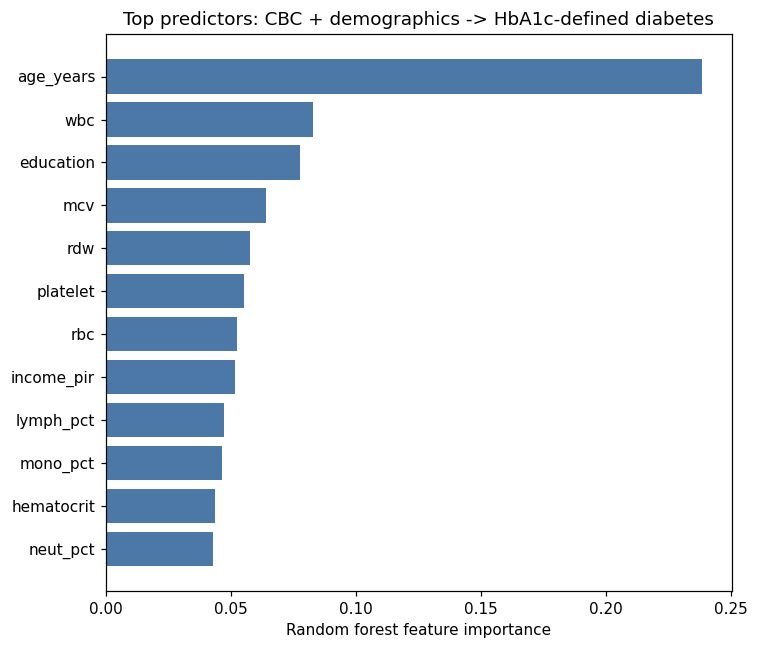

In [9]:
feature_names = numeric_features + categorical_features
importances = rf_pipe.named_steps["clf"].feature_importances_
imp_df = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
print(imp_df.to_string(index=False))

plt.figure(figsize=(7, 6))
plt.barh(imp_df["feature"][:12][::-1], imp_df["importance"][:12][::-1], color="#4C78A8")
plt.xlabel("Random forest feature importance")
plt.title("Top predictors: CBC + demographics -> HbA1c-defined diabetes")
plt.tight_layout()
plt.show()


## Interpretation and limitations

On the held-out 1,670 participants (179 positive labels), AUROC is **0.689** for age alone,
**0.743** for demographics, **0.783** for CBC + demographics logistic regression, and
**0.811** for the CBC + demographics random forest. CBC increases AUROC by **0.040** in the
matched logistic comparison; the full logistic model gains **0.094** over age alone. This
suggests predictive signal beyond age on this split, without establishing statistical significance.

At score threshold 0.5, age-only logistic regression would defer 902 tests and miss 48 positive
labels (sensitivity 0.732, NPV 0.947). CBC + demographics logistic regression would defer
1,094 and miss 50 (sensitivity 0.721, NPV 0.954). The forest would defer 1,563 and miss 132
(sensitivity 0.263, NPV 0.916). These examples show why higher AUROC or NPV alone cannot justify
a deferral policy; the common threshold does not match sensitivity or calibrate clinical risk.

The age-only baseline and both multivariable logistic models use the same training-only
imputation/scaling and balanced class weights. See the executed comparison above and
`../results/baseline/baseline_auroc_comparison.csv` for the measured discrimination gains. The CBC logistic
versus demographics logistic comparison is the matched model-family ablation; the forest
comparison combines additional predictors with a different model family.

High NPV alone does not establish safe test deferral. Read it alongside sensitivity, tests
deferred, and positive cases missed. Age's impurity-based forest importance does not prove
that a multivariable model is necessary or establish a causal effect.

These are unweighted, single-split exploratory results on the current cohort, including
participants with a prior diabetes diagnosis. Intended screening eligibility, survey design,
calibration, cross-validation, and uncertainty remain unresolved. No threshold is selected
from these test results for deployment.

## Next steps

- Confirm the intended population and HbA1c primary endpoint with the team, then rerun comparisons.
- Apply NHANES survey weights and account for sampling design.
- Add stratified k-fold cross-validation and confidence intervals, refitting preprocessing within each fold.
- One-hot encode categorical demographic variables rather than treating their codes as ordinal.
- Assess calibration using development data before selecting a recommendation threshold.
- Add gradient boosting to the model comparison.
